
# Decision Tree Classifier

## Step 1 - Import Libraries

In [18]:

import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.datasets import load_iris

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')



## Step 2 - Load Iris Dataset from Seaborn

We will use only the feature columns from seaborn.


In [19]:

iris_df = sns.load_dataset("iris")

iris_df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



## Step 3 - Extract X Features from Seaborn Dataset


In [20]:

X = iris_df.drop(
    columns=["species"]
)

X.head()


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



## Step 4 - Load Target (y) from Scikit-Learn Iris Dataset

Target Mapping:

0 = Setosa

1 = Versicolor

2 = Virginica


In [21]:

iris_sklearn = load_iris()

# X = iris_sklearn.data
y = iris_sklearn.target

print(y)


[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]



## Step 5 - Understand Dataset Shapes


In [22]:

print("X Shape:", X.shape)

print("y Shape:", y.shape)


X Shape: (150, 4)
y Shape: (150,)



## Step 6 - Explore Class Distribution


In [23]:

pd.Series(y).value_counts()


0    50
1    50
2    50
Name: count, dtype: int64


## Step 7 - Train Test Split


In [24]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("Training Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)


Training Shape: (105, 4)
Testing Shape : (45, 4)



## Step 8 - Create Decision Tree Classifier

criterion='gini'


In [25]:

model = DecisionTreeClassifier(random_state=42)

model


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current


## Step 9 - Train the Model


In [26]:

model.fit(
    X_train,
    y_train
)

print("Model Trained Successfully")


Model Trained Successfully



## Step 10 - Make Predictions


In [27]:

predictions = model.predict(X_test)

print(predictions[:10])


[1 0 2 1 1 0 1 2 1 1]



## Step 11 - Accuracy Score


In [28]:

accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)


Accuracy: 1.0



## Step 12 - Visualize Decision Tree


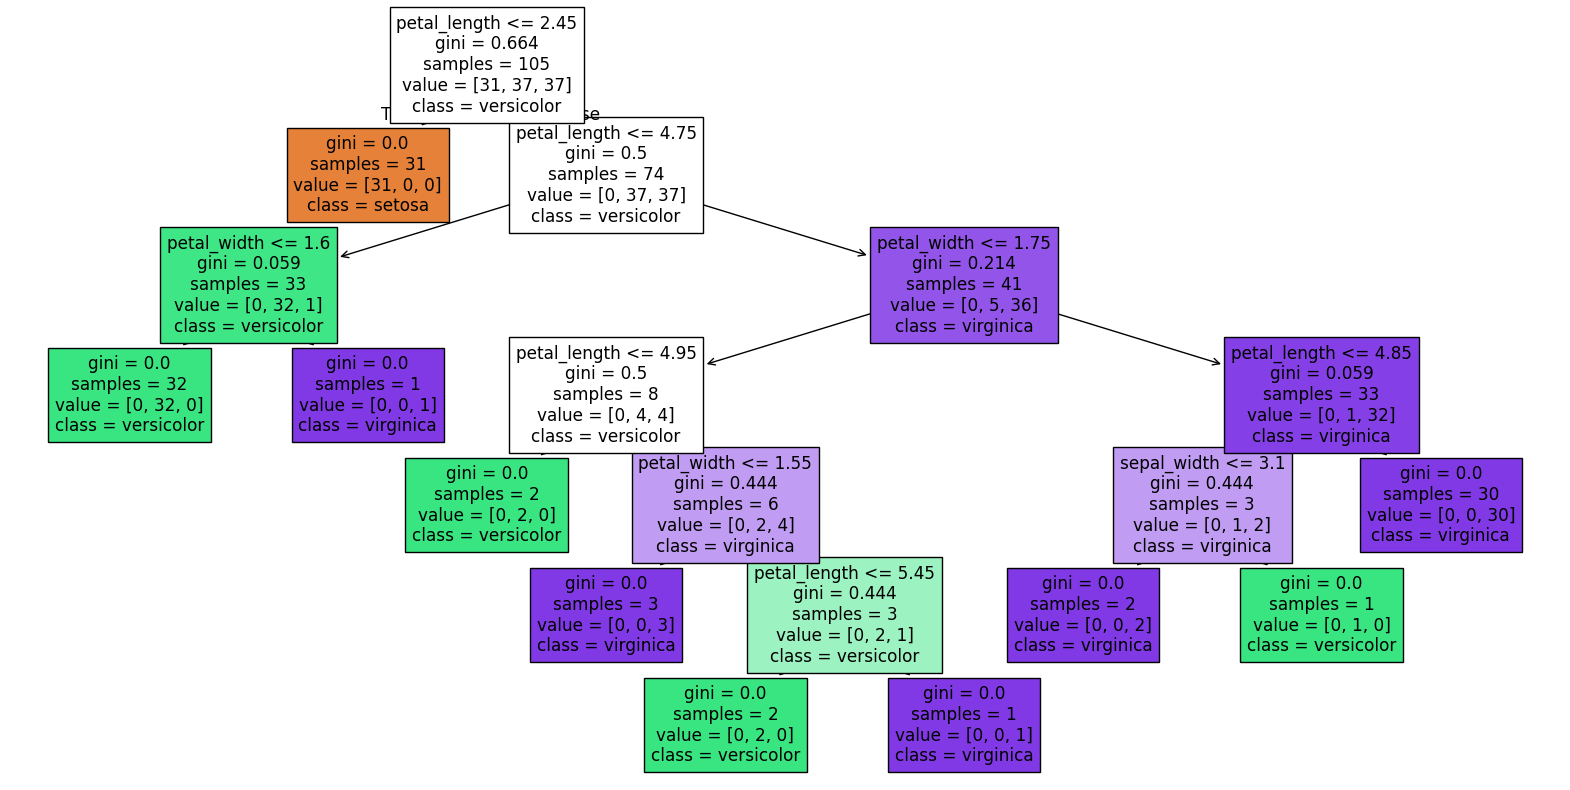

In [35]:

plt.figure(figsize=(20,10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=iris_sklearn.target_names,
    filled=True
)

plt.show()



## Step 13 - Feature Importance


In [30]:

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
)


,Feature,Importance
2,petal_length,0.893264
3,petal_width,0.087626
1,sepal_width,0.019110
0,sepal_length,0.000000


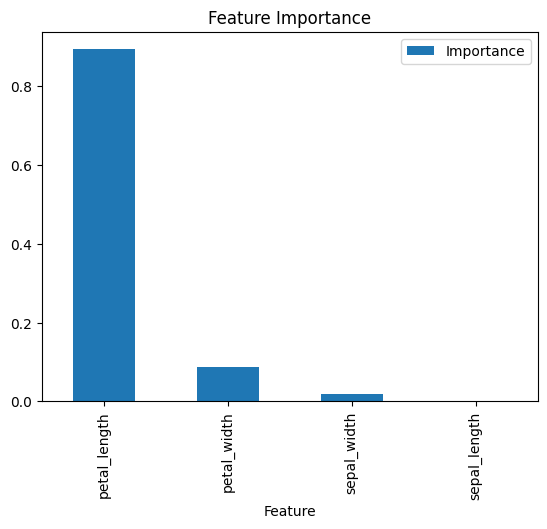

In [31]:

importance.sort_values(
    by='Importance',
    ascending=False
).plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.title("Feature Importance")

plt.show()



## Step 14 - Predict a New Flower


In [32]:

new_flower = [[
    5.1,
    3.5,
    1.4,
    0.2
]]

prediction = model.predict(
    new_flower
)

species = iris_sklearn.target_names[
    prediction[0]
]

print("Predicted Species:", species)


Predicted Species: setosa



## Step 15 - Compare Gini vs Entropy


In [33]:

gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

gini_model.fit(X_train,y_train)
entropy_model.fit(X_train,y_train)

gini_pred = gini_model.predict(X_test)
entropy_pred = entropy_model.predict(X_test)

print(
    "Gini Accuracy:",
    accuracy_score(
        y_test,
        gini_pred
    )
)

print(
    "Entropy Accuracy:",
    accuracy_score(
        y_test,
        entropy_pred
    )
)


Gini Accuracy: 1.0
Entropy Accuracy: 0.9777777777777777



## Step 16 - Hyperparameter Tuning Example


In [34]:

tuned_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

tuned_model.fit(
    X_train,
    y_train
)

tuned_predictions = tuned_model.predict(
    X_test
)

print(
    "Tuned Accuracy:",
    accuracy_score(
        y_test,
        tuned_predictions
    )
)


Tuned Accuracy: 1.0



## Step 17 - Understanding Overfitting

Very deep tree:

max_depth=None

May memorize training data.

Controlled tree:

max_depth=3 or 4

Usually generalizes better.
